# Strict GRG Policy Comparison: Reconstruction and Forecasting

Executed analysis of 15 saved missions and three shared history-only controls. The original three-policy experiment is preserved.

In [1]:
from pathlib import Path
import csv, hashlib, json
import numpy as np
from IPython.display import Image, Markdown, display
root = Path.cwd()
run = root / '11.2_result/strict_run_20261103T024044Z'
read = lambda p: json.loads(p.read_text())
config = read(run / 'config_frozen.json')
print('Pinned run:', run.name)
print('Preset MI:EMSE weights:', config['weights_mi_emse'])
print('Mission starts (h):', config['window_start_hours'])

Pinned run: strict_run_20261103T024044Z
Preset MI:EMSE weights: {'mi': [1.0, 0.0], 'emse': [0.0, 1.0], 'fusion': [0.5, 0.5], 'fusion_40_60': [0.4, 0.6], 'fusion_60_40': [0.6, 0.4]}
Mission starts (h): [72.0, 80.0, 88.0]


## Controlled protocol

Five preset arms: MI, EMSE, MI:EMSE 50:50, 40:60, and 60:40. The order is always MI then EMSE. Fusion uses `J = w_MI * MI/s_MI + w_EMSE * EMSE_reduction/s_EMSE`; raw MI and EMSE have different units and are not directly added. Normalizers are the unchanged maximum initial single-event gains, shared by all arms within each window and frozen before sampling. No test temperature selects weights or normalizers.

All arms reuse the same three-day/2,000-observation GP checkpoint, fixed kernel parameters, 29 candidate sensors, synthetic map and obstacles, Home, navigation, 0.35 m/s speed, 5 s dwell, 900 s budget, GRG depth 2 and two time splits. The only policy change is route scoring. Successful recorded acquisitions condition the posterior; there is no kernel refit. Every arm computes both score components.

Three preset mission starts are 72, 80 and 88 hours from the dataset origin (day-four 00:00, 08:00 and 16:00 in the original timestamp convention; timezone unspecified). Each is an independent replay reset to the same checkpoint, not a multi-window online trajectory. The last two therefore start with older information. The three windows are correlated parts of one dataset, not independent repeated trials. No confidence interval or statistical-superiority claim is justified by these three windows alone.

The original clock counts travel, acquisition waiting and dwell but charges online computation as zero. Planning wall time is saved separately. This is Python recorded-data replay, not a real-time or ROS/Nav2 experiment. Both the planning/execution acquisition schedule and return-to-Home budget are checked.


## Reconstruction versus causal future forecasting

**Reconstruction:** after the 15-minute mission, evaluate the latest odd-index held-out observation per reachable sensor in the last five minutes before the common deadline. Predictions use each record's actual timestamp. This is retrospective window reconstruction; it is neither a simultaneous dense measured field nor a causal forecast for those pre-cutoff records.

**Forecasting:** the common forecast origin is mission start plus 15 minutes. Reload each saved final GP and freeze it. Evaluate only odd-index held-out records in `(0,15]`, `(15,30]` and `(30,60]` minutes after that origin. No future observations are appended and no parameters change. The history-only GP uses the same origins and test records. Acquisition pools are truncated at the common cutoff, and acquisition/test record IDs are disjoint. Forecast truths are used solely for evaluation.

**Objective versus evaluation:** EMSE still targets the same reachable grid at the mission deadline. The future forecast scores are additional outcomes; this run does not change EMSE into a future-horizon objective. Model-based expected squared error / latent variance is distinct from empirical error on held-out temperatures. Lower target variance does not guarantee lower measured RMSE.

**Metrics:** primary empirical RMSE and MAE use identical records for all policies within each task/window. NLPD and 95% predictive coverage use observation variance, including learned noise. Sensor-balanced RMSE gives sensors equal weight despite unequal logging rates. The summary below is the arithmetic mean of three window RMSEs, not pooled-record RMSE. Per-window results and record counts are retained to expose variation.

**Spatial scope:** the preserved split alternates records within each sensor; sensors themselves are not held out from acquisition. Nearby records are correlated, and dense measured ground truth is unavailable. Reconstruction therefore tests the recorded reachable locations, not spatial extrapolation to entirely unseen sensors or true error over the entire map. The future bins provide the separate temporal holdout. A later spatial-generalization claim would require a separate held-out-location protocol.


In [2]:
assert read(run / 'verification.json')['passed']
for relative, digest in read(run / 'artifacts_sha256.json').items():
    assert hashlib.sha256((run / relative).read_bytes()).hexdigest() == digest, relative
print('All original strict-run artifact hashes and verification checks pass.')

All original strict-run artifact hashes and verification checks pass.


## Mean of three window RMSEs

Each window contributes equal weight to this descriptive mean; the windows are not independent trials.

| Policy (MI:EMSE) | Reconstruction | Forecast (0,15] min | Forecast (15,30] min | Forecast (30,60] min |
|---|---:|---:|---:|---:|
| History only | 5.137181 | 5.474390 | 5.240287 | 5.239110 |
| MI | 1.239073 | 1.395163 | 1.860237 | 1.953275 |
| EMSE | 1.152650 | 1.353696 | 1.896846 | 1.993748 |
| MI:EMSE 50:50 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |
| MI:EMSE 40:60 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |
| MI:EMSE 60:40 | 1.217038 | 1.343509 | 1.824843 | 1.873229 |

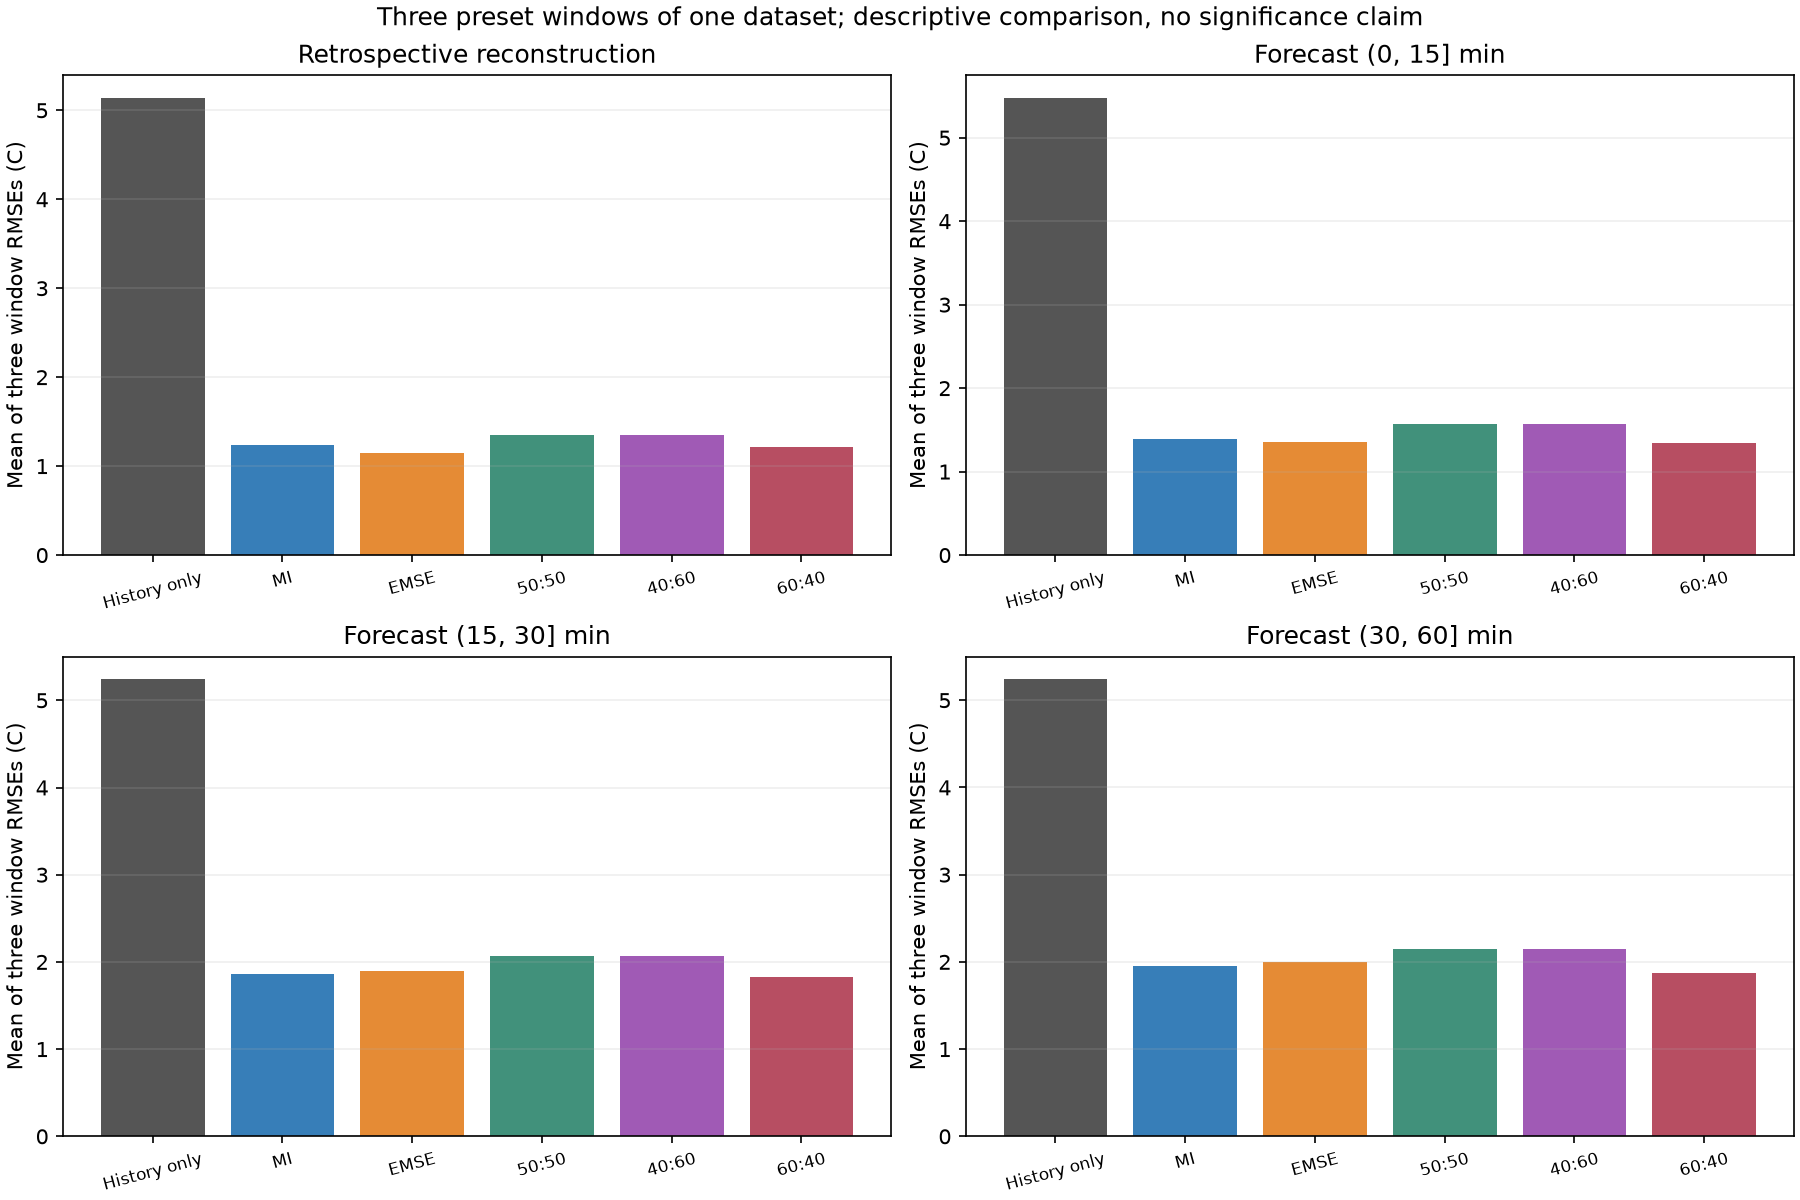

In [3]:
display(Markdown('| Policy (MI:EMSE) | Reconstruction | Forecast (0,15] min | Forecast (15,30] min | Forecast (30,60] min |\n|---|---:|---:|---:|---:|\n| History only | 5.137181 | 5.474390 | 5.240287 | 5.239110 |\n| MI | 1.239073 | 1.395163 | 1.860237 | 1.953275 |\n| EMSE | 1.152650 | 1.353696 | 1.896846 | 1.993748 |\n| MI:EMSE 50:50 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |\n| MI:EMSE 40:60 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |\n| MI:EMSE 60:40 | 1.217038 | 1.343509 | 1.824843 | 1.873229 |'))
display(Image(filename=str(run / 'figures/strict_comparison.png')))

## Per-window forecasting

| Window | Policy | Reconstruction RMSE | Forecast (0,15] | Forecast (15,30] | Forecast (30,60] |
|---|---|---:|---:|---:|---:|
| w00 | History only | 0.489578 | 0.463602 | 0.473355 | 0.463175 |
| w00 | MI | 0.546907 | 0.567876 | 0.578728 | 0.614442 |
| w00 | EMSE | 0.527523 | 0.486340 | 0.543291 | 0.627064 |
| w00 | MI:EMSE 50:50 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w00 | MI:EMSE 40:60 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w00 | MI:EMSE 60:40 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w08 | History only | 7.644961 | 8.111826 | 7.824759 | 7.767400 |
| w08 | MI | 1.242893 | 1.351817 | 2.773157 | 3.061642 |
| w08 | EMSE | 0.989282 | 1.305019 | 2.855750 | 3.158509 |
| w08 | MI:EMSE 50:50 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |
| w08 | MI:EMSE 40:60 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |
| w08 | MI:EMSE 60:40 | 1.242893 | 1.351817 | 2.773157 | 3.061642 |
| w16 | History only | 7.277005 | 7.847742 | 7.422747 | 7.486755 |
| w16 | MI | 1.927421 | 2.265797 | 2.228827 | 2.183742 |
| w16 | EMSE | 1.941144 | 2.269729 | 2.291498 | 2.195671 |
| w16 | MI:EMSE 50:50 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |
| w16 | MI:EMSE 40:60 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |
| w16 | MI:EMSE 60:40 | 1.911620 | 2.176834 | 2.188111 | 2.028881 |

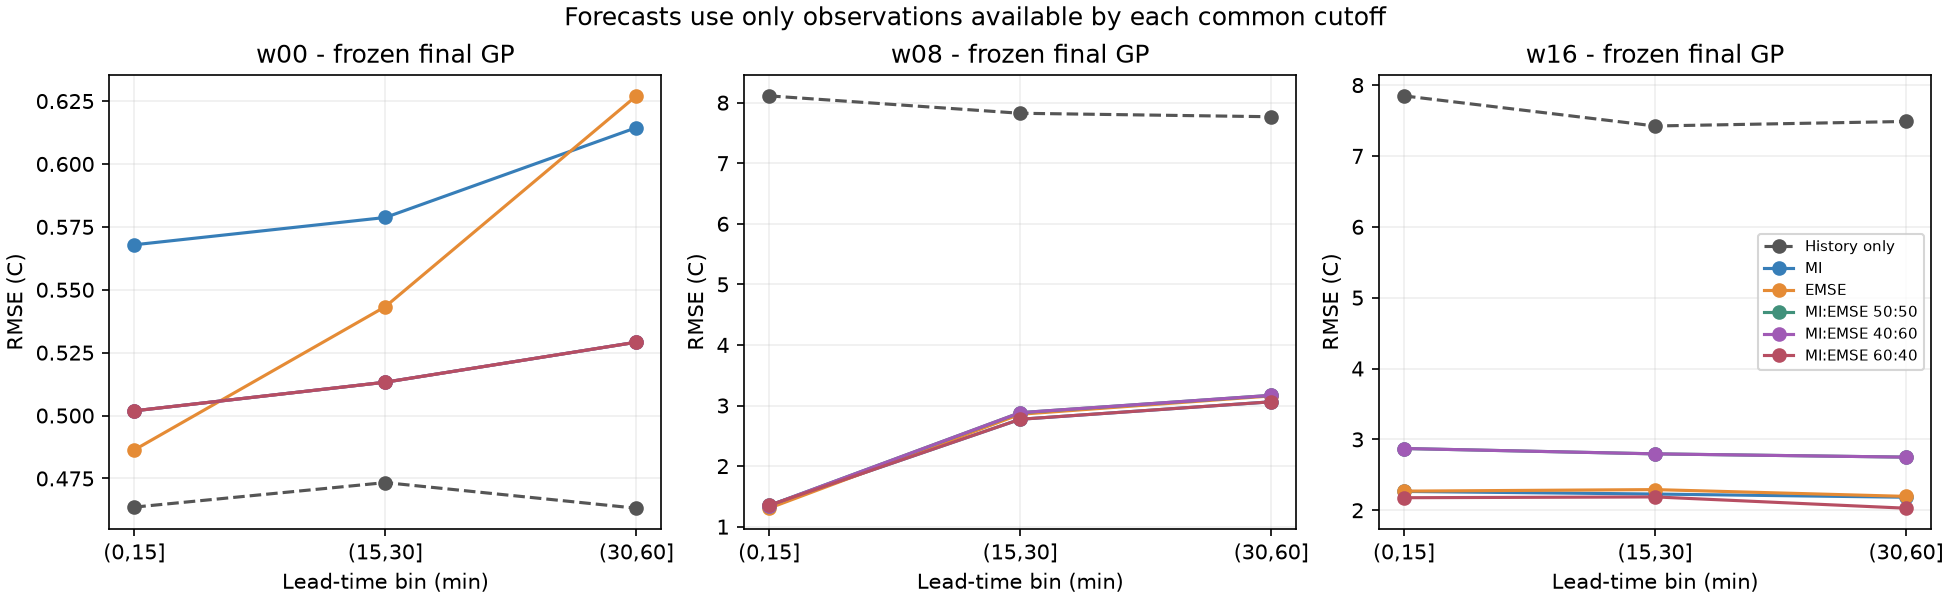

In [4]:
display(Markdown('| Window | Policy | Reconstruction RMSE | Forecast (0,15] | Forecast (15,30] | Forecast (30,60] |\n|---|---|---:|---:|---:|---:|\n| w00 | History only | 0.489578 | 0.463602 | 0.473355 | 0.463175 |\n| w00 | MI | 0.546907 | 0.567876 | 0.578728 | 0.614442 |\n| w00 | EMSE | 0.527523 | 0.486340 | 0.543291 | 0.627064 |\n| w00 | MI:EMSE 50:50 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w00 | MI:EMSE 40:60 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w00 | MI:EMSE 60:40 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w08 | History only | 7.644961 | 8.111826 | 7.824759 | 7.767400 |\n| w08 | MI | 1.242893 | 1.351817 | 2.773157 | 3.061642 |\n| w08 | EMSE | 0.989282 | 1.305019 | 2.855750 | 3.158509 |\n| w08 | MI:EMSE 50:50 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |\n| w08 | MI:EMSE 40:60 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |\n| w08 | MI:EMSE 60:40 | 1.242893 | 1.351817 | 2.773157 | 3.061642 |\n| w16 | History only | 7.277005 | 7.847742 | 7.422747 | 7.486755 |\n| w16 | MI | 1.927421 | 2.265797 | 2.228827 | 2.183742 |\n| w16 | EMSE | 1.941144 | 2.269729 | 2.291498 | 2.195671 |\n| w16 | MI:EMSE 50:50 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |\n| w16 | MI:EMSE 40:60 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |\n| w16 | MI:EMSE 60:40 | 1.911620 | 2.176834 | 2.188111 | 2.028881 |'))
display(Image(filename=str(run / 'figures/forecast_by_window.png')))

## Actual measured records and acquisition accounting

| Window | Task | Held-out records | Sensors | Actual timestamps (h) |
|---|---|---:|---:|---|
| w00 | reconstruction | 28 | 28 | 72.19963200 - 72.24956030 |
| w00 | forecast_0_15m | 256 | 29 | 72.25008451 - 72.49955174 |
| w00 | forecast_15_30m | 263 | 29 | 72.50020059 - 72.74932354 |
| w00 | forecast_30_60m | 526 | 29 | 72.75692906 - 73.24933042 |
| w08 | reconstruction | 29 | 29 | 80.19065438 - 80.24964820 |
| w08 | forecast_0_15m | 261 | 29 | 80.25003490 - 80.49981727 |
| w08 | forecast_15_30m | 245 | 29 | 80.50710137 - 80.74996864 |
| w08 | forecast_30_60m | 496 | 29 | 80.75709886 - 81.24940934 |
| w16 | reconstruction | 29 | 29 | 88.16683780 - 88.24989319 |
| w16 | forecast_0_15m | 244 | 29 | 88.25730049 - 88.49995427 |
| w16 | forecast_15_30m | 244 | 29 | 88.50016968 - 88.74998324 |
| w16 | forecast_30_60m | 497 | 29 | 88.75729475 - 89.24983136 |

| Window | Policy | Acquisitions | Simulated mission (s) | Planning wall time (s) |
|---|---|---:|---:|---:|
| w00 | MI | 7 | 870.259 | 3.513 |
| w00 | EMSE | 7 | 870.259 | 2.455 |
| w00 | MI:EMSE 50:50 | 7 | 870.259 | 2.919 |
| w00 | MI:EMSE 40:60 | 7 | 870.259 | 3.024 |
| w00 | MI:EMSE 60:40 | 7 | 870.259 | 2.898 |
| w08 | MI | 11 | 899.389 | 5.299 |
| w08 | EMSE | 9 | 899.389 | 4.511 |
| w08 | MI:EMSE 50:50 | 8 | 899.389 | 3.643 |
| w08 | MI:EMSE 40:60 | 8 | 899.389 | 3.482 |
| w08 | MI:EMSE 60:40 | 11 | 899.389 | 5.146 |
| w16 | MI | 10 | 898.821 | 4.523 |
| w16 | EMSE | 7 | 863.581 | 3.711 |
| w16 | MI:EMSE 50:50 | 8 | 898.821 | 3.122 |
| w16 | MI:EMSE 40:60 | 8 | 898.821 | 3.139 |
| w16 | MI:EMSE 60:40 | 9 | 898.821 | 4.186 |

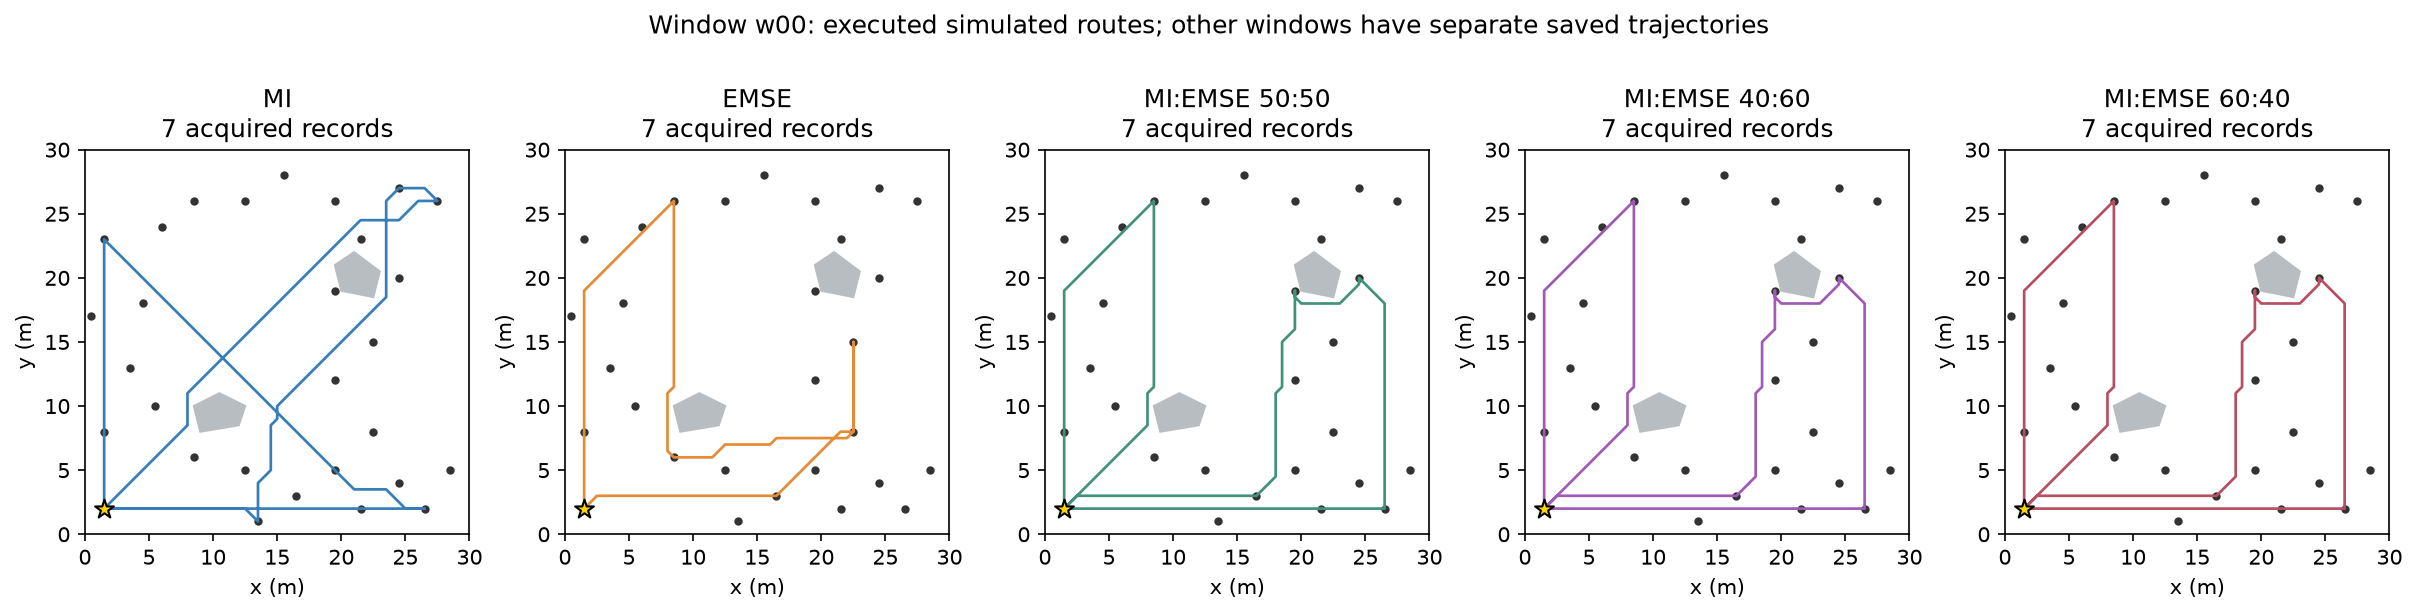

In [5]:
display(Image(filename=str(run / 'figures/five_routes_w00.png')))

## Independently recompute RMSE and verify future boundaries

In [6]:
verified = 0
for metric in read(run / 'evaluation.json'):
    folder = run / 'windows' / metric['window'] / metric['policy']
    with (folder / (metric['task'] + '_predictions.csv')).open() as stream:
        predictions = list(csv.DictReader(stream))
    error = np.array([float(r['predicted_temperature_c']) - float(r['temperature_c']) for r in predictions])
    rmse = float(np.sqrt(np.mean(error**2)))
    assert np.isclose(rmse, metric['rmse_c'], atol=1e-10)
    if metric['task'].startswith('forecast'):
        lo, hi = [int(v.rstrip('m')) for v in metric['task'].split('_')[1:]]
        origin = metric['forecast_origin_h']
        assert all(origin + lo/60 < float(r['t_h']) <= origin + hi/60 for r in predictions)
    verified += 1
print('Verified', verified, 'task/model/window results from saved real-record predictions.')

Verified 72 task/model/window results from saved real-record predictions.


## Interpretation

- Retrospective reconstruction: lowest mean window RMSE among sampling arms is **EMSE**, 1.152650 C; history only is 5.137181 C.
- Forecast (0, 15] min: lowest mean window RMSE among sampling arms is **MI:EMSE 60:40**, 1.343509 C; history only is 5.474390 C.
- Forecast (15, 30] min: lowest mean window RMSE among sampling arms is **MI:EMSE 60:40**, 1.824843 C; history only is 5.240287 C.
- Forecast (30, 60] min: lowest mean window RMSE among sampling arms is **MI:EMSE 60:40**, 1.873229 C; history only is 5.239110 C.

No general winner is established. Freeze the chosen protocol before evaluating separate days or field data. The deadline EMSE objective and future forecasting remain distinct.

The five timestamp/split/weight tests and seven analytic objective tests pass. Each window also passes independent GPyTorch-versus-cached covariance/Schur-complement checks. Every mission checks frozen hyperparameters, unique and chronological acquisitions, valid posterior updates, held-out separation, feasible collision-free routes, matching schedules and budgeted return. Forecast verification checks that the final training timestamps are no later than the common origin and that evaluating future records leaves GP training data and parameters unchanged.

Saved prediction CSVs independently reproduce every task metric. The first window's MI, EMSE and 50:50 arms reproduce the earlier three-policy records, routes, trajectories and metrics within 1e-7; wall time is excluded. Input/source SHA-256 checks preserve the earlier successful run, original README/Notebook/latest pointer, and reused older experiment files.
